> Adapted from *Dive into Deep Learning*, section [GPUs](https://d2l.ai/chapter_builders-guide/use-gpu.html). Not affiliated with or endorsed by the book's authors.
> Source, authors, licenses and changes: [Attribution and changes](#Attribution-and-changes), at the end of this notebook.

Previous: [Section 6.6: File I/O](06.06_read-write.ipynb) | Next: [Section 7.1: From Fully Connected Layers to Convolutions](../07_convolutional-neural-networks/07.01_why-conv.ipynb)

# GPUs

In [Table 1.1.1](https://d2l.ai/chapter_introduction/index.html#tab-intro-decade), we illustrated the rapid growth
of computation over the past two decades.
In a nutshell, GPU performance has increased
by a factor of 1000 every decade since 2000.
This offers great opportunities but it also suggests
that there was significant demand for such performance.


In this section, we begin to discuss how to harness
this computational performance for your research.
First by using a single GPU and at a later point,
how to use multiple GPUs and multiple servers (with multiple GPUs).

Specifically, we will discuss how
to use a single NVIDIA GPU for calculations.
First, make sure you have at least one NVIDIA GPU installed.
Then, download the [NVIDIA driver and CUDA](https://developer.nvidia.com/cuda-downloads)
and follow the prompts to set the appropriate path.
Once these preparations are complete,
the `nvidia-smi` command can be used
to view the graphics card information.


In PyTorch, every array has a device; we often refer it as a *context*.
So far, by default, all variables
and associated computation
have been assigned to the CPU.
Typically, other contexts might be various GPUs.
Things can get even hairier when
we deploy jobs across multiple servers.
By assigning arrays to contexts intelligently,
we can minimize the time spent
transferring data between devices.
For example, when training neural networks on a server with a GPU,
we typically prefer for the model's parameters to live on the GPU.

To run the programs in this section as the book does,
you need at least two GPUs.
Note that this might be extravagant for most desktop computers
but it is easily available in the cloud, e.g.,
by using the AWS EC2 multi-GPU instances.
Almost all other sections do *not* require multiple GPUs, but here we simply wish to illustrate data flow between different devices.

<img src="../tablet.svg" alt="divelet-ml" title="Added by divelet-ml, not in the book"> **In JupyterLite there is no GPU**: neither Pyodide nor xeus-python can use one, so `d2l.num_gpus()` is 0 and all computation is on the CPU. The code below that needs a GPU is shown but not run; the rest runs and shows what the helpers return without a GPU.

In [ ]:
import numpy as np
from divelet_ml import nn

import divelet_ml as d2l

## Computing Devices

We can specify devices, such as CPUs and GPUs,
for storage and calculation.
By default, tensors are created in the main memory
and then the CPU is used for calculations.


In PyTorch, the CPU and GPU can be indicated by `torch.device('cpu')` and `torch.device('cuda')`.
<img src="../tablet.svg" alt="divelet-ml" title="Added by divelet-ml, not in the book"> In `divelet_ml`, a device is only a name: `'cpu'` and `'cuda'`.
It should be noted that the `cpu` device
means all physical CPUs and memory.
This means that PyTorch's calculations
will try to use all CPU cores.
However, a `gpu` device only represents one card
and the corresponding memory.
If there are multiple GPUs, we use `torch.device(f'cuda:{i}')`
to represent the $i^\textrm{th}$ GPU ($i$ starts at 0).
Also, `gpu:0` and `gpu` are equivalent.

In [ ]:
d2l.cpu(), d2l.gpu(), d2l.gpu(1)

We can query the number of available GPUs.

In [ ]:
d2l.num_gpus()

Now two convenient functions allow us
to run code even if the requested GPUs do not exist.

In [ ]:
d2l.try_gpu(), d2l.try_gpu(10), d2l.try_all_gpus()

## Tensors and GPUs

By default, tensors are created on the CPU.
We can query the device where the tensor is located.

In [ ]:
x = np.array([1, 2, 3])
x.device

It is important to note that whenever we want
to operate on multiple terms,
they need to be on the same device.
For instance, if we sum two tensors,
we need to make sure that both arguments
live on the same device---otherwise the framework
would not know where to store the result
or even how to decide where to perform the computation.

### Storage on the GPU

There are several ways to store a tensor on the GPU.
For example, we can specify a storage device when creating a tensor.
Next, we create the tensor variable `X`; a NumPy array always lives in main memory, so it has no `device` argument.
The tensor created on a GPU only consumes the memory of this GPU.
We can use the `nvidia-smi` command to view GPU memory usage.
In general, we need to make sure that we do not create data that exceeds the GPU memory limit.

In [ ]:
X = np.ones((2, 3))
X

Assuming that you have at least two GPUs, the following code will create a random tensor, `Y`, on the second GPU.

```python
Y = torch.rand(2, 3, device=try_gpu(1))
Y
```

### Copying

[**If we want to compute `X + Y`,
we need to decide where to perform this operation.**]
For instance, as shown in the figure below,
we can transfer `X` to the second GPU
and perform the operation there.
*Do not* simply add `X` and `Y`,
since this will result in an exception.
The runtime engine would not know what to do:
it cannot find data on the same device and it fails.
Since `Y` lives on the second GPU,
we need to move `X` there before we can add the two.

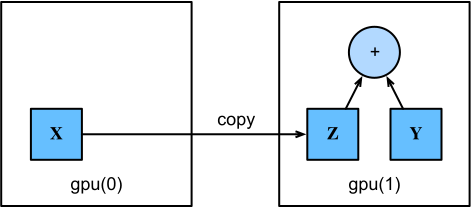

```python
Z = X.cuda(1)
print(X)
print(Z)
```

Now that the data (both `Z` and `Y`) are on the same GPU), we can add them up.

```python
Y + Z
```

But what if your variable `Z` already lived on your second GPU?
What happens if we still call `Z.cuda(1)`?
It will return `Z` instead of making a copy and allocating new memory.

```python
Z.cuda(1) is Z
```

### Side Notes

People use GPUs to do machine learning
because they expect them to be fast.
But transferring variables between devices is slow: much slower than computation.
So we want you to be 100% certain
that you want to do something slow before we let you do it.
If the deep learning framework just did the copy automatically
without crashing then you might not realize
that you had written some slow code.

Transferring data is not only slow, it also makes parallelization a lot more difficult,
since we have to wait for data to be sent (or rather to be received)
before we can proceed with more operations.
This is why copy operations should be taken with great care.
As a rule of thumb, many small operations
are much worse than one big operation.
Moreover, several operations at a time
are much better than many single operations interspersed in the code
unless you know what you are doing.
This is the case since such operations can block if one device
has to wait for the other before it can do something else.
It is a bit like ordering your coffee in a queue
rather than pre-ordering it by phone
and finding out that it is ready when you are.

Last, when we print tensors or convert tensors to the NumPy format,
if the data is not in the main memory,
the framework will copy it to the main memory first,
resulting in additional transmission overhead.
Even worse, it is now subject to the dreaded global interpreter lock
that makes everything wait for Python to complete.


## Neural Networks and GPUs

Similarly, a neural network model can specify devices.
The following code puts the model parameters on the GPU.

```python
net = nn.Sequential(nn.LazyLinear(1))
net = net.to(device=try_gpu())
```

We will see many more examples of
how to run models on GPUs in the following chapters,
simply because the models will become somewhat more computationally intensive.

For example, when the input is a tensor on the GPU, the model will calculate the result on the same GPU.

```python
net(X)
```

Let's confirm that the model parameters are stored on the same GPU.

```python
net[0].weight.data.device
```

In short, as long as all data and parameters are on the same device, we can learn models efficiently. In the following chapters we will see several such examples.

## Summary

We can specify devices for storage and calculation, such as the CPU or GPU.
  By default, data is created in the main memory
  and then uses the CPU for calculations.
The deep learning framework requires all input data for calculation
  to be on the same device,
  be it CPU or the same GPU.
You can lose significant performance by moving data without care.
  A typical mistake is as follows: computing the loss
  for every minibatch on the GPU and reporting it back
  to the user on the command line (or logging it in a NumPy `ndarray`)
  will trigger a global interpreter lock which stalls all GPUs.
  It is much better to allocate memory
  for logging inside the GPU and only move larger logs.

## Exercises

1. Try a larger computation task, such as the multiplication of large matrices,
   and see the difference in speed between the CPU and GPU.
   What about a task with a small number of calculations?
1. How should we read and write model parameters on the GPU?
1. Measure the time it takes to compute 1000
   matrix--matrix multiplications of $100 \times 100$ matrices
   and log the Frobenius norm of the output matrix one result at a time. Compare it with keeping a log on the GPU and transferring only the final result.
1. Measure how much time it takes to perform two matrix--matrix multiplications
   on two GPUs at the same time. Compare it with computing in in sequence
   on one GPU. Hint: you should see almost linear scaling.



Discussions of the original section: [book's forum](https://discuss.d2l.ai/t/63)

Previous: [Section 6.6: File I/O](06.06_read-write.ipynb) | Next: [Section 7.1: From Fully Connected Layers to Convolutions](../07_convolutional-neural-networks/07.01_why-conv.ipynb)

## Attribution and changes

Adapted from *Dive into Deep Learning*, section
[GPUs](https://d2l.ai/chapter_builders-guide/use-gpu.html)
(source: [`chapter_builders-guide/use-gpu.md`](https://github.com/d2l-ai/d2l-en/blob/23d7a5aecceee57d1292c56e90cce307f183bb0a/chapter_builders-guide/use-gpu.md)
at commit `23d7a5aeccee`), by Aston Zhang, Zachary C. Lipton, Mu Li, Alexander J. Smola and contributors.
Text and figures: [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Code: adapted from the book's sample code, MIT-0.
Not affiliated with or endorsed by the book's authors.

**Changes from the original** (PyTorch edition):
- Code uses NumPy instead of PyTorch, so it runs in JupyterLite (Pyodide and xeus-python). The word *tensor* is kept and means a NumPy `ndarray`.
- `d2l` is divelet-ml's package (`import divelet_ml as d2l`) instead of the book's `d2l.torch`.
- A browser kernel has no GPU. `d2l.cpu()`, `gpu(i)`, `num_gpus()` (always 0), `try_gpu` and `try_all_gpus` are divelet-ml's helpers: a device is only the name `'cpu'` or `'cuda:i'`, in place of the book's `torch.device`, and the cells that run on GPUs (a tensor on the second GPU, `cuda(1)`, `net.to(device)`) are shown as code in the text and not run. The `Trainer` extension that moves a batch and the model to a GPU is dropped with its sentence.
- `x.device` is NumPy's, which is `'cpu'`; `torch.tensor` and `torch.ones` are `np.array` and `np.ones`.
- The figures are embedded in the notebook as PNG data URIs, rendered from the book's image files, so the notebook loads no other file; references to them say "the figure above" or "the figure below".
- Cross-references to other sections link to the book's site, and citations are written inline (author and year); the book's bibliography lists them.
- The d2lbook framework tabs for MXNet, TensorFlow and JAX are removed.